<center><h1> Full RC Time Series Diffusion Models <h1><center>

In [1]:
%load_ext autoreload
%autoreload 2

# Table of Contents
1. [Intro](#Introduction)
2. [Data](#Data)
3. [Model Specifications](#Model-Specifications)
4. [Training](#Training)
5. [Testing](#Testing)

In [61]:
from tests.utils import print_tree 

print_tree()

├── data
│   ├── 10_dim_realized_covar.csv
│   └── SP500_RV_5min.xlsx
├── docs
│   ├── 01. Diffusion
│   │   ├── Cao et al. (2024), A Survey on Generative Diffusion Models.pdf
│   │   ├── Chen et al. (2024), An Overview of Diffusion Models Applications, Guided Generation, Statistical Rates and Optimization.pdf
│   │   ├── Ho et al. (2020), Denoising Diffusion Probabilistic Models.pdf
│   │   ├── Ho et al. (2022), Classifier Free Diffusion Guidance.pdf
│   │   ├── Kingma et al. (2022), Variational Diffusion Models.pdf
│   │   ├── Luo (2022), Understanding Diffusion Models A Unified Perspective.pdf
│   │   ├── Nakkiran et al. (2024) Step-by-Step Diffusion An Elementary Tutorial.pdf
│   │   ├── Nichol et Dhariwal (2021), Improved Denoising Diffusion Probabilistic Models.pdf
│   │   ├── Sohl Dickenstein et al. (2015), Deep Unsupervised Learning using Nonequilibrium Thermodynamics.pdf
│   │   ├── Song et al. (2021), Denoising Diffusion Implicit Models.pdf
│   │   ├── Song et al. (2021), Sco

# Introduction

In [ ]:
import torch 
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import os

In [ ]:
# ---- EDIT THESE ----
DEVICE_NAME = "cuda"  
GPU_ID = 0   # (0 or 1)
N_THREADS = 4 
# --------------------

# Make CUDA's numbering match nvidia-smi (default ordering can differ)
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = str(GPU_ID) if DEVICE_NAME == "cuda" else ""
os.environ["OMP_NUM_THREADS"] = str(N_THREADS)
os.environ["MKL_NUM_THREADS"] = str(N_THREADS)

torch.set_num_threads(N_THREADS)

if DEVICE_NAME == "cuda":
    assert torch.cuda.is_available(), "CUDA requested but not available"
    device = torch.device("cuda:0")   # see note below
    free, total = torch.cuda.mem_get_info()
    print(f"Using {torch.cuda.get_device_name(0)} (physical GPU {GPU_ID}); "
          f"free {free/1e9:.1f} / {total/1e9:.1f} GB")
else:
    device = torch.device("cpu")
    print("Using CPU")

# Data

In [4]:
from rcdiff.data.rv import RVSP500

rvSP500 = RVSP500()
(dates_train, RV_train), (dates_test, RV_test) = rvSP500.get_realized_variance_data(len_train=2000, standardize=False)

# Model Specifications

In [5]:
from rcdiff.diff import DDPM, BaseScheduler

K = 100

scheduler = BaseScheduler(K = K)
ddpm = DDPM(scheduler=scheduler)

In [6]:
from rcdiff import ESN 
from rcdiff import RandomWeight, ParametersESN

R = 25 
T, N = RV_train.shape

A = RandomWeight(dist="normal", sparsity=0, norm_type="spectral_radius")
C = RandomWeight(dist="uniform", sparsity=0, norm_type="l2")
zeta = RandomWeight(dist="uniform", sparsity=0, norm_type="euclidean")

esnParams = ParametersESN(A_RW = A, 
                 C_RW = C,
                 zeta_RW = zeta,
                 leak_rate = 0.3, 
                 rho = 0.9, 
                 gamma = 0.1,
                 omega = 0) 

esn = ESN(in_dim = N, 
          reservoir_size= R, 
          params=esnParams
          )

In [45]:
from rcdiff import RWDenoisingNetwork, ParametersRWDN

H = 50

A_k = RandomWeight("uniform", sparsity=0, norm_type="l2")
b_k = RandomWeight("uniform", sparsity=0, norm_type="euclidean")

rwdnParams = ParametersRWDN(A_k = A_k,
               b_k = b_k,
               gamma = 0.5, 
               omega = 0.3)

rwdn = RWDenoisingNetwork(in_dim = N, 
                          hidden_size = H, 
                          reservoir_size = R,
                          params = rwdnParams, 
                          K = K)

In [46]:
from rcdiff.models.config import TrainConfig

train_spec = TrainConfig(t0 = 100,
                        seed = 1234,
                        device = "cpu")  

In [47]:
from rcdiff import RCDiff 

rcdiffusion = RCDiff(diff = ddpm, esn = esn, denoiser = rwdn, spec = train_spec)

# Training

In [48]:
df_loss, time = rcdiffusion.fit(x = RV_train, c = None)

100


100%|██████████| 100/100 [00:00<00:00, 183.64it/s]


Training complete Time: 0.56s
100


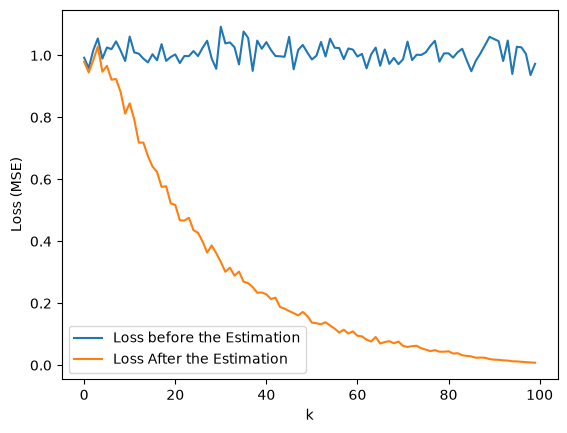

In [49]:
plt.plot(df_loss['k'], df_loss['LossBefore'], label = 'Loss before the Estimation')
plt.plot(df_loss['k'], df_loss['LossAfter'], label = 'Loss After the Estimation')
plt.ylabel('Loss (MSE)')
plt.xlabel('k')
plt.legend()
plt.show()

# Testing

A one step ahead can be performed by: 

In [56]:
x_hat, full_reverse = rcdiffusion.conditional_distribution(x = RV_train, c = None, n_samples=50)
print('Actual obs', round(RV_test[0].item(),2))
print('Predicted obs', round(x_hat[0].mean().item(), 2))

Actual obs 0.67
Predicted obs 0.34


In [57]:
obs = 1000 # len(RV_test) # 1000 
test = RV_test[:obs]

forecast = rcdiffusion.one_step_ahead_forecast(x_train = RV_train, x_test = test)

100%|██████████| 1000/1000 [01:36<00:00, 10.38it/s]


In [58]:
import torch.nn.functional as F 

F_m = forecast.mean(dim = 1)

F.mse_loss(F_m, test) # should be around 3.6 to be good

tensor(7.4458)

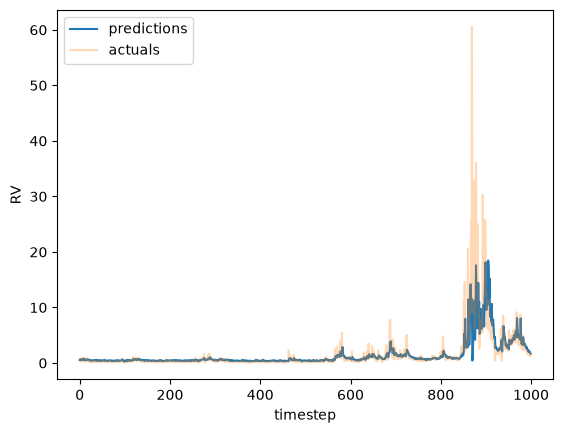

In [59]:
plt.plot(F_m.detach().numpy(), label = 'predictions')
plt.plot(test.detach().numpy(), label = 'actuals', alpha = 0.3)
plt.ylabel('RV')
plt.xlabel('timestep')
plt.legend()
plt.show()